In [20]:
!pip -q install alpaca-py torch pandas numpy scikit-learn matplotlib


In [21]:
import os
from getpass import getpass

ALPACA_API_KEY = getpass("Alpaca API Key: ")
ALPACA_SECRET_KEY = getpass("Alpaca Secret Key: ")

SYMBOL = "ABAT"

os.environ["ALPACA_API_KEY"] = ALPACA_API_KEY
os.environ["ALPACA_SECRET_KEY"] = ALPACA_SECRET_KEY

print("Symbol:", SYMBOL)

Alpaca API Key: ··········
Alpaca Secret Key: ··········
Symbol: ABAT


In [22]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from datetime import datetime, timedelta, timezone

from alpaca.data.historical import StockHistoricalDataClient
from alpaca.data.requests import StockBarsRequest
from alpaca.data.timeframe import TimeFrame

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

from sklearn.preprocessing import StandardScaler

In [23]:
client = StockHistoricalDataClient(
    ALPACA_API_KEY,
    ALPACA_SECRET_KEY
)

print("Connected to Alpaca")


Connected to Alpaca


In [24]:
end = datetime.now(timezone.utc)

# Start with 30 days
start = end - timedelta(days=30)

request = StockBarsRequest(
    symbol_or_symbols=SYMBOL,
    timeframe=TimeFrame.Minute,
    start=start,
    end=end,
    feed="iex"
)

bars = client.get_stock_bars(request)

df = bars.df.reset_index()

df.head()

,symbol,timestamp,open,high,low,close,volume,trade_count,vwap
0,ABAT,2026-09-01 13:30:00+00:00,2.600,2.600,2.595,2.595,1300.0,4.0,2.596154
1,ABAT,2026-09-01 13:31:00+00:00,2.590,2.590,2.590,2.590,281.0,2.0,2.590000
2,ABAT,2026-09-01 13:32:00+00:00,2.610,2.610,2.595,2.595,1250.0,3.0,2.602800
3,ABAT,2026-09-01 13:33:00+00:00,2.600,2.600,2.590,2.590,1800.0,7.0,2.595278
4,ABAT,2026-09-01 13:34:00+00:00,2.585,2.585,2.575,2.575,622.0,4.0,2.581667


In [25]:
df = df.sort_values("timestamp").copy()

# -------------------------------
# BASIC PRICE FEATURES
# -------------------------------

df["return_1"] = df["close"].pct_change(1)

df["return_2"] = df["close"].pct_change(2)

df["return_5"] = df["close"].pct_change(5)

df["return_10"] = df["close"].pct_change(10)

df["return_30"] = df["close"].pct_change(30)

df["return_60"] = df["close"].pct_change(60)

# -------------------------------
# VOLATILITY
# -------------------------------

df["volatility_5"] = (
    df["return_1"]
    .rolling(5)
    .std()
)

df["volatility_10"] = (
    df["return_1"]
    .rolling(10)
    .std()
)

df["volatility_30"] = (
    df["return_1"]
    .rolling(30)
    .std()
)

df["volatility_60"] = (
    df["return_1"]
    .rolling(60)
    .std()
)

# -------------------------------
# MOVING AVERAGES
# -------------------------------

df["ma_5"] = (
    df["close"]
    .rolling(5)
    .mean()
)

df["ma_10"] = (
    df["close"]
    .rolling(10)
    .mean()
)

df["ma_30"] = (
    df["close"]
    .rolling(30)
    .mean()
)

df["ma_60"] = (
    df["close"]
    .rolling(60)
    .mean()
)

# Distance from moving averages

df["distance_ma_5"] = (
    df["close"] / df["ma_5"] - 1
)

df["distance_ma_30"] = (
    df["close"] / df["ma_30"] - 1
)

df["distance_ma_60"] = (
    df["close"] / df["ma_60"] - 1
)

# -------------------------------
# VOLUME
# -------------------------------

df["volume_change"] = (
    df["volume"]
    .pct_change()
)

df["volume_ma_5"] = (
    df["volume"]
    .rolling(5)
    .mean()
)

df["volume_ma_30"] = (
    df["volume"]
    .rolling(30)
    .mean()
)

df["relative_volume"] = (
    df["volume"] /
    (df["volume_ma_30"] + 1e-8)
)

# -------------------------------
# RANGE
# -------------------------------

df["range"] = (
    df["high"] - df["low"]
)

df["range_pct"] = (
    df["range"] /
    df["close"]
)

# -------------------------------
# POSITION WITHIN RECENT RANGE
# -------------------------------

rolling_high = (
    df["high"]
    .rolling(30)
    .max()
)

rolling_low = (
    df["low"]
    .rolling(30)
    .min()
)

df["range_position"] = (
    (df["close"] - rolling_low) /
    (rolling_high - rolling_low + 1e-8)
)

In [26]:
FEATURES = [
    "close",

    "return_1",
    "return_2",
    "return_5",
    "return_10",
    "return_30",
    "return_60",

    "volatility_5",
    "volatility_10",
    "volatility_30",
    "volatility_60",

    "ma_5",
    "ma_10",
    "ma_30",
    "ma_60",

    "distance_ma_5",
    "distance_ma_30",
    "distance_ma_60",

    "volume",
    "volume_change",
    "volume_ma_5",
    "volume_ma_30",
    "relative_volume",

    "range",
    "range_pct",
    "range_position",
]

len(FEATURES)

26

In [27]:
PREDICTION_DELAY = 2

df["target_price"] = df["close"].shift(-PREDICTION_DELAY)

In [28]:
LOOKBACK = 60
DELAY = 2

data = df.dropna().reset_index(drop=True)

X = []
y = []
timestamps = []

for i in range(
    LOOKBACK + DELAY - 1,
    len(data) - DELAY
):

    # ---------------------------
    # INFORMATION AVAILABLE
    # ---------------------------

    end_idx = i - DELAY

    start_idx = end_idx - LOOKBACK + 1

    window = data.iloc[
        start_idx:end_idx + 1
    ]

    # ---------------------------
    # TARGET
    # ---------------------------

    target = data.iloc[i]["close"]

    # ---------------------------
    # FEATURES
    # ---------------------------

    features = window[FEATURES].values

    X.append(features)

    y.append(target)

    timestamps.append(
        data.iloc[i]["timestamp"]
    )

X = np.array(X, dtype=np.float32)

y = np.array(y, dtype=np.float32)

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (3352, 60, 26)
y shape: (3352,)


In [29]:
split = int(
    len(X) * 0.8
)

X_train = X[:split]
X_test = X[split:]

y_train = y[:split]
y_test = y[split:]

print("Train:", X_train.shape)
print("Test :", X_test.shape)

Train: (2681, 60, 26)
Test : (671, 60, 26)


In [30]:
n_samples, seq_len, n_features = X_train.shape

scaler = StandardScaler()

X_train_2d = X_train.reshape(
    -1,
    n_features
)

scaler.fit(X_train_2d)

X_train = scaler.transform(
    X_train_2d
).reshape(
    n_samples,
    seq_len,
    n_features
)

X_test = scaler.transform(
    X_test.reshape(-1, n_features)
).reshape(
    X_test.shape
)

In [31]:
class MarketDataset(Dataset):

    def __init__(self, X, y):

        self.X = torch.tensor(
            X,
            dtype=torch.float32
        )

        self.y = torch.tensor(
            y,
            dtype=torch.float32
        )

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):

        return (
            self.X[idx],
            self.y[idx]
        )


train_dataset = MarketDataset(
    X_train,
    y_train
)

test_dataset = MarketDataset(
    X_test,
    y_test
)

train_loader = DataLoader(
    train_dataset,
    batch_size=64,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=64,
    shuffle=False
)

In [32]:
class PriceGRU(nn.Module):

    def __init__(
        self,
        input_size,
        hidden_size=128
    ):

        super().__init__()

        self.gru = nn.GRU(
            input_size=input_size,
            hidden_size=hidden_size,
            num_layers=2,
            batch_first=True,
            dropout=0.2
        )

        self.fc = nn.Sequential(

            nn.Linear(
                hidden_size,
                64
            ),

            nn.ReLU(),

            nn.Linear(
                64,
                32
            ),

            nn.ReLU(),

            nn.Linear(
                32,
                1
            )
        )

    def forward(self, x):

        output, _ = self.gru(x)

        last = output[:, -1, :]

        return self.fc(last).squeeze(1)

In [33]:
device = torch.device(
    "cuda"
    if torch.cuda.is_available()
    else "cpu"
)

model = PriceGRU(
    input_size=len(FEATURES)
).to(device)

print(device)


cuda


In [35]:
model.eval()

predictions = []

actuals = []

with torch.no_grad():

    for xb, yb in test_loader:

        xb = xb.to(device)

        pred = model(xb)

        predictions.extend(
            pred.cpu().numpy()
        )

        actuals.extend(
            yb.numpy()
        )

predictions = np.array(predictions)

actuals = np.array(actuals)

In [34]:
optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=0.001,
    weight_decay=1e-5
)

loss_function = nn.HuberLoss()

EPOCHS = 500

for epoch in range(EPOCHS):

    model.train()

    total_loss = 0

    for xb, yb in train_loader:

        xb = xb.to(device)

        yb = yb.to(device)

        optimizer.zero_grad()

        prediction = model(xb)

        loss = loss_function(
            prediction,
            yb
        )

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            1.0
        )

        optimizer.step()

        total_loss += loss.item()

    avg_loss = (
        total_loss /
        len(train_loader)
    )

    print(
        f"Epoch {epoch+1:02d}/{EPOCHS} "
        f"Loss: {avg_loss:.6f}"
    )

Epoch 01/500 Loss: 1.382513
Epoch 02/500 Loss: 0.469378
Epoch 03/500 Loss: 0.032709
Epoch 04/500 Loss: 0.017351
Epoch 05/500 Loss: 0.012857
Epoch 06/500 Loss: 0.034040
Epoch 07/500 Loss: 0.014488
Epoch 08/500 Loss: 0.017032
Epoch 09/500 Loss: 0.020485
Epoch 10/500 Loss: 0.044499
Epoch 11/500 Loss: 0.015572
Epoch 12/500 Loss: 0.012968
Epoch 13/500 Loss: 0.010932
Epoch 14/500 Loss: 0.007942
Epoch 15/500 Loss: 0.007444
Epoch 16/500 Loss: 0.007713
Epoch 17/500 Loss: 0.008508
Epoch 18/500 Loss: 0.009132
Epoch 19/500 Loss: 0.007855
Epoch 20/500 Loss: 0.007329
Epoch 21/500 Loss: 0.007103
Epoch 22/500 Loss: 0.007559
Epoch 23/500 Loss: 0.008500
Epoch 24/500 Loss: 0.010016
Epoch 25/500 Loss: 0.012432
Epoch 26/500 Loss: 0.018025
Epoch 27/500 Loss: 0.038832
Epoch 28/500 Loss: 0.104577
Epoch 29/500 Loss: 0.145659
Epoch 30/500 Loss: 0.369026
Epoch 31/500 Loss: 0.250620
Epoch 32/500 Loss: 0.099441
Epoch 33/500 Loss: 0.022072
Epoch 34/500 Loss: 0.013127
Epoch 35/500 Loss: 0.049810
Epoch 36/500 Loss: 0

In [36]:
mae = np.mean(
    np.abs(
        predictions - actuals
    )
)

rmse = np.sqrt(
    np.mean(
        (predictions - actuals) ** 2
    )
)

print("MAE :", mae)
print("RMSE:", rmse)

MAE : 0.18912232
RMSE: 0.20179328


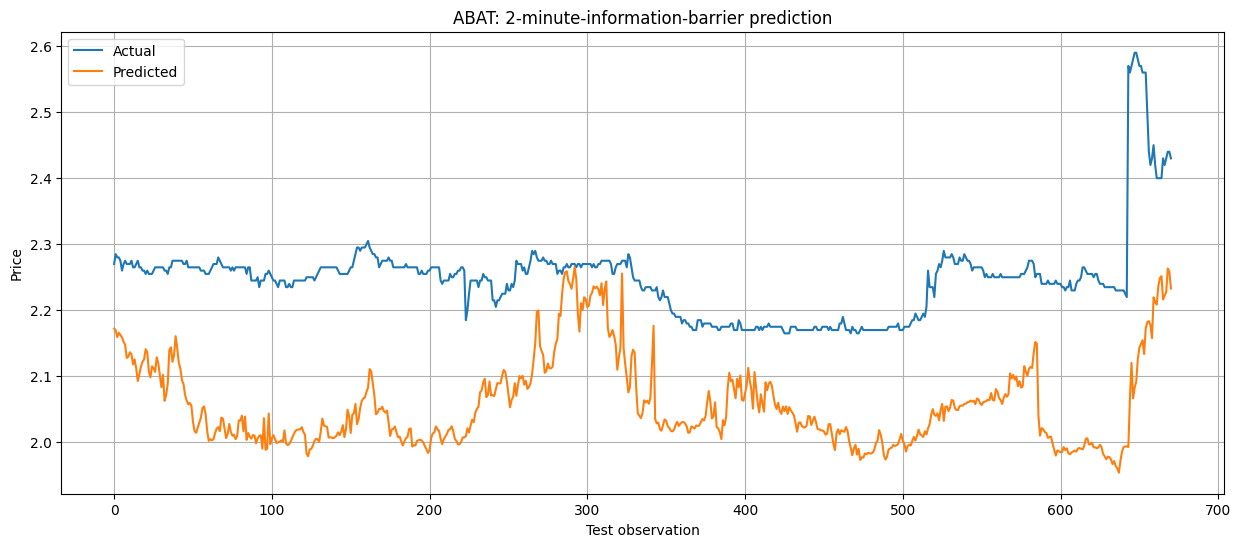

In [37]:
plt.figure(figsize=(15, 6))

plt.plot(
    actuals,
    label="Actual"
)

plt.plot(
    predictions,
    label="Predicted"
)

plt.title(
    f"{SYMBOL}: 2-minute-information-barrier prediction"
)

plt.xlabel("Test observation")

plt.ylabel("Price")

plt.legend()

plt.grid()

plt.show()

In [38]:
actual_direction = (
    np.diff(actuals) > 0
)

predicted_direction = (
    np.diff(predictions) > 0
)

direction_accuracy = np.mean(
    actual_direction ==
    predicted_direction
)

print(
    "Directional accuracy:",
    f"{direction_accuracy * 100:.2f}%"
)


Directional accuracy: 45.82%
